# Projet Data Mining - Saint-Honoré

## Questions 7 et 8

### 1. Préparation de l'environnement et des données

In [ ]:
# Importation des bibliothèques
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
# Chargement des données nettoyées
df = pd.read_csv("../data/clean/clients_clean.csv")
df.head()

,client_id,boutique_principale,anciennete_mois,nb_achats_12m,panier_moyen_eur,retours,demandes_sav,carte_fidelite,canal_prefere,pays_residence,montant_prochain_achat_eur,est_revenu_6m,montant_total_eur,ville,surface_m2,vendeurs,ouverte_depuis_mois,pays_boutique
0,CT80059,BT15,4,4,1468.0,0,0,aucune,en ligne,USA,725.0,oui,5872.0,Séoul,483,8,236,Corée
1,CT80578,BT28,80,3,1235.0,1,1,argent,boutique,France,1479.0,oui,3705.0,Cannes,267,14,182,France
2,CT80256,BT27,43,1,1814.0,0,2,or,boutique,France,2307.0,oui,1814.0,Dubaï,519,12,209,EAU
3,CT80098,BT16,1,1,1795.0,0,0,or,boutique,Italie,1820.0,non,1795.0,Paris,139,21,266,France
4,CT80362,BT31,51,3,2022.0,0,0,argent,boutique,Chine,1201.0,oui,6066.0,Dubaï,108,17,73,EAU


In [ ]:
# Exploration des données
print(df.shape)

for col in df.columns:
    print(col)

(700, 18)
client_id
boutique_principale
anciennete_mois
nb_achats_12m
panier_moyen_eur
retours
demandes_sav
carte_fidelite
canal_prefere
pays_residence
montant_prochain_achat_eur
est_revenu_6m
montant_total_eur
ville
surface_m2
vendeurs
ouverte_depuis_mois
pays_boutique


In [5]:
# Importation des outils de Machine Learning
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

### 2. Question 7 - Segmentation des clients

L'objectif est d'identifier des groupes de clients présentant des comportements similaires à l'aide d'une méthode de clustering.

In [6]:
# Sélection des variables pour le clustering

variables = [
    "anciennete_mois",
    "nb_achats_12m",
    "panier_moyen_eur",
    "retours",
    "demandes_sav"
]

X = df[variables]
X.head()

,anciennete_mois,nb_achats_12m,panier_moyen_eur,retours,demandes_sav
0,4,4,1468.0,0,0
1,80,3,1235.0,1,1
2,43,1,1814.0,0,2
3,1,1,1795.0,0,0
4,51,3,2022.0,0,0


In [7]:
# Standardisation des variables

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print(X_scaled[:5])

[[-1.10229382  0.11483504 -0.62441876 -0.63924005 -0.63906729]
 [ 2.02695011 -0.22868858 -0.7482204   0.66914602  0.95291528]
 [ 0.50350241 -0.91573583 -0.44057597 -0.63924005  2.54489784]
 [-1.22581661 -0.91573583 -0.45067138 -0.63924005 -0.63906729]
 [ 0.83289651 -0.22868858 -0.33005777 -0.63924005 -0.63906729]]


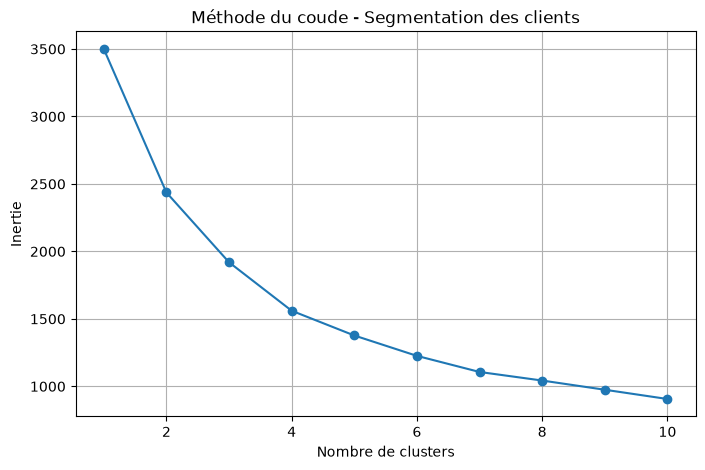

In [ ]:
# Méthode du coude

#Tester plusieurs nombres de groupes

inerties = []

for k in range(1, 11):
    km = KMeans(n_clusters=k, n_init=10, random_state=42)
    km.fit(X_scaled)
    inerties.append(km.inertia_)

#Construction du graphique

plt.figure(figsize=(8, 5))
plt.plot(range(1, 11), inerties, marker="o")
plt.xlabel("Nombre de clusters")
plt.ylabel("Inertie")
plt.title("Méthode du coude - Segmentation des clients")
plt.grid()
plt.show()

#### Interprétation de la méthode du coude

La courbe présente un changement de pente autour de 4 clusters.
Au-delà, la diminution de l'inertie devient moins importante.

Une segmentation en 4 groupes semble donc pertinente.
Ce choix sera évalué à l'aide du score de silhouette.

In [9]:
# Evaluation des clusters par le score de silhouette

scores = []

for k in range(2, 11):
    km = KMeans(n_clusters=k, n_init=10, random_state=42)
    labels = km.fit_predict(X_scaled)
    score = silhouette_score(X_scaled, labels)
    scores.append(score)
    print(k, round(score, 3))

2 0.459
3 0.3
4 0.297
5 0.299
6 0.304
7 0.298
8 0.308
9 0.309
10 0.307


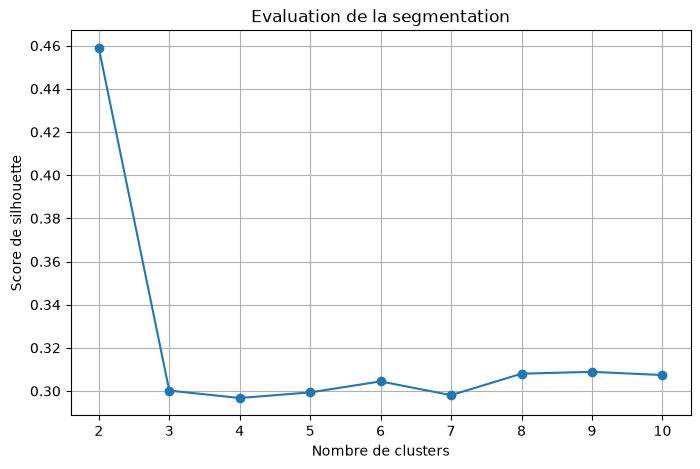

In [10]:
# Visualisation des scores de silhouette

plt.figure(figsize=(8, 5))
plt.plot(range(2, 11), scores, marker="o")
plt.xlabel("Nombre de clusters")
plt.ylabel("Score de silhouette")
plt.title("Evaluation de la segmentation")
plt.xticks(range(2, 11))
plt.grid()
plt.show()

#### Interprétation du score de silhouette

Le score de silhouette atteint son maximum pour
k = 2, avec une valeur de 0,459.

Contrairement à la méthode du coude, qui suggère
4 clusters, le score de silhouette favorise une
segmentation en 2 groupes.

Une comparaison des profils obtenus avec ces deux
configurations permettra de retenir la segmentation
la plus pertinente pour Saint-Honoré.